# Replay and the carved statue

Notebook 05 carved the pawn model and saved every step in a log.

Here we play that log back in Swift, look at what is left of the block, and put the model on top of it.

## Setup

In [1]:
import logging
import warnings
from pathlib import Path

# A few docstrings in the toolbox trigger SyntaxWarnings when Python compiles them; not related to our code
warnings.filterwarnings("ignore", category=SyntaxWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import roboticstoolbox as rtb
import spatialmath as sm
import swift
import trimesh
from matplotlib.patches import Rectangle
from sculptor.carving import load_log
from sculptor.cell import Cell
from sculptor.evaluation import summarize
from sculptor.model import MODELS, STATUE_HEIGHT, Voxels, grid_centers, inside, place
from sculptor.scene import (
    RECORDINGS,
    add_block,
    add_chisel,
    add_model,
    add_table,
    fix_mesh_paths,
    place_block,
    place_chisel,
    recording,
    replay,
    show_gif,
)

# Closing a Swift window leaves a few websocket tasks pending; they are harmless
logging.getLogger("asyncio").setLevel(logging.CRITICAL)

# Without this, Swift on Windows cannot load any mesh (see sculptor/scene.py)
fix_mesh_paths()

# The Swift recordings are saved in results/recordings/; True records them again
RECORD: bool = False

# The log of the carving of the pawn model, saved by notebook 05
LOG = Path("..") / "results" / "05_table_control" / "carving_pawn.npz"

# Statue cubes, marble left and the outline of the model in the plots, checked with palette_check.py
STATUE_COLOR, MARBLE_COLOR, MODEL_COLOR = "#a0522d", "#9a9a8e", "#2f6db3"

# The model in Swift, a darker brown than the statue cubes and only a bit see-through, so it shows
# where it sticks out of them
MODEL_RGBA = [0.36, 0.20, 0.10, 0.75]

## 1. The log

Notebook 05 saved the log of the carving of the pawn model. This notebook only reads it, so its counts have to be the ones of section 3.2 of notebook 05.

In [2]:
log = load_log(LOG)
pd.Series(summarize(log)).to_frame("pawn model")

,pawn model
closed_loop,True
posture_task,True
noise_std,0.0
seed,0
statue_cubes,208
statue_removed,0
statue_damage_fraction,0.0
marble_cubes,1607
marble_removed,1596
marble_remaining,11


The counts are the ones of section 3.2 of notebook 05: 1596 of the 1607 marble cubes removed and none of the 208 statue cubes, so the saved log is the carving of that notebook.

## 2. The carved statue

The cubes the log never removed are what is left of the block: the statue and the marble the chisel could not reach.

We compare their volume with the volume of the model, and cut the block through the axis of the table with the outline of the model on top, taken from a grid of 5 mm cubes as in notebook 02.

In [3]:
voxels = log.voxels
left = log.removed_at < 0   # the cubes the log never removed
pawn = place(trimesh.load(MODELS / "Chess_Pawn.stl", force="mesh"), STATUE_HEIGHT)

cube_volume = voxels.size**3 * 1e3  # [L]
statue_left = int((left & voxels.is_statue).sum())
marble_left = int((left & ~voxels.is_statue).sum())
pd.DataFrame({"cubes": [statue_left, marble_left, np.nan],
              "volume [L]": [statue_left * cube_volume, marble_left * cube_volume, pawn.volume * 1e3]},
             index=["statue", "marble left", "model"]).round(3)

,cubes,volume [L]
statue,208.0,5.616
marble left,11.0,0.297
model,NaN,5.665


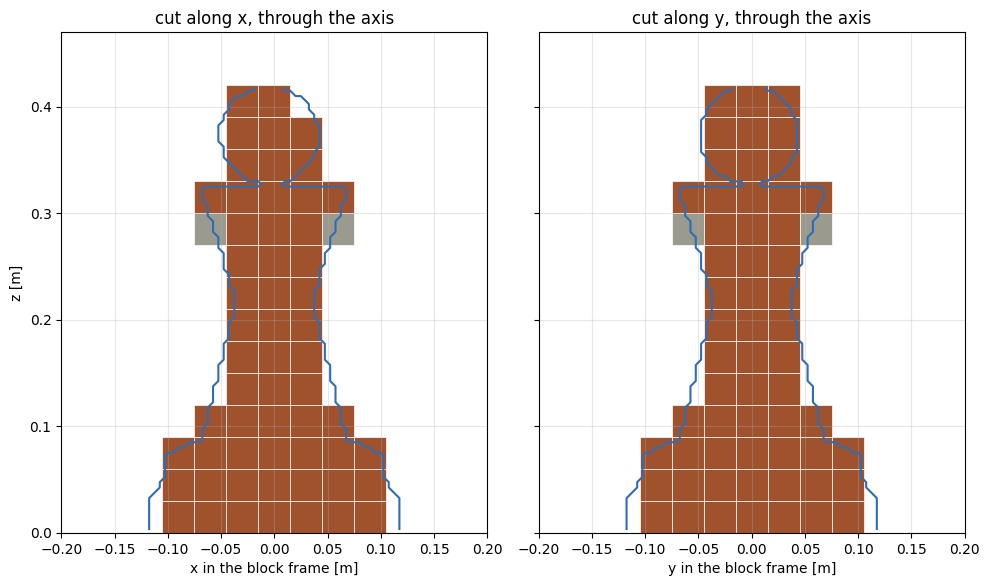

In [4]:
# The outline of the model, from a grid of 5 mm cubes
REFERENCE = 0.005
fine_centers = grid_centers(pawn, REFERENCE)
fine = inside(pawn, fine_centers)
middle = fine.shape[0] // 2

fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=True)
for ax, (axis, name) in zip(axes, [(0, "x"), (1, "y")]):
    # The cubes left on the vertical plane through the axis of the table
    other = 1 - axis
    on_cut = np.isclose(voxels.centers[:, other], 0.0) & left
    for c, statue in zip(voxels.centers[on_cut], voxels.is_statue[on_cut]):
        ax.add_patch(Rectangle((c[axis] - voxels.size / 2, c[2] - voxels.size / 2), voxels.size, voxels.size,
                               facecolor=STATUE_COLOR if statue else MARBLE_COLOR, edgecolor="white", lw=0.5))
    outline = fine[:, middle, :] if axis == 0 else fine[middle, :, :]
    across = fine_centers[:, 0, 0, 0] if axis == 0 else fine_centers[0, :, 0, 1]
    ax.contour(across, fine_centers[0, 0, :, 2], outline.T.astype(float), levels=[0.5],
               colors=MODEL_COLOR, linewidths=1.5)
    ax.set_xlim(-0.2, 0.2)
    ax.set_ylim(0.0, 0.47)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.set_title(f"cut along {name}, through the axis")
    ax.set_xlabel(f"{name} in the block frame [m]")
axes[0].set_ylabel("z [m]")
fig.tight_layout()
plt.show()

The statue cubes add up to 5.616 L, close to the 5.665 L of the model, but with another shape. A cube is statue when its center is inside the model (notebook 02), so some cubes stick out of the outline and some parts of the model are left out, like the edge of the base and the neck under the head.

The 11 marble cubes left, 0.297 L, are the blocked cubes of notebook 05. The cuts show four of them, under the collar on both sides; the other seven are on the diagonals of the block, out of these two planes.

## 3. Replay with the model on top

The whole carving played back from the log, one step in every 150, with the cubes going at the step the log removed them (`replay` in `src/sculptor/scene.py`). At the end the arm steps back and the model goes on top of what is left, see-through (`add_model`).


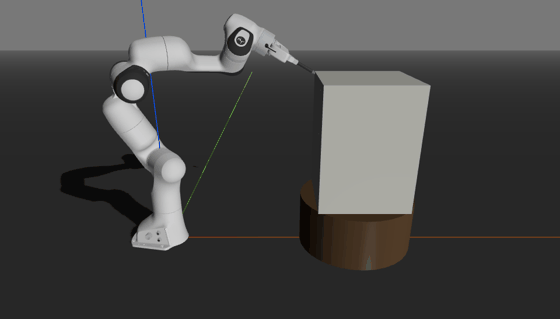

In [5]:
GIF = RECORDINGS / "07_replay_carving.gif"
# One step in every EVERY is drawn, so the whole carving fits in a short GIF
EVERY = 150

if RECORD or not GIF.exists():
    panda = rtb.models.Panda()
    cell = Cell()
    env = swift.Swift()
    env.launch(realtime=True, browser=None)
    panda.q = log.q[0]
    env.add(panda)
    add_table(env, cell)
    cubes, ids = add_block(env, voxels, cell, log.phi[0])
    chisel = add_chisel(env, panda.fkine(panda.q, tool=cell.tip))
    env.step(0.05)

    with recording(env, GIF):
        replay(env, log, cubes, ids, panda, chisel, cell, every=EVERY)
        # The arm steps back and the model goes on top of what is left
        panda.q = panda.qr
        place_chisel(chisel, panda.fkine(panda.q, tool=cell.tip))
        add_model(env, MODELS / "Chess_Pawn.stl", STATUE_HEIGHT, cell, log.phi[-1], rgba=MODEL_RGBA)
        for _ in range(30):
            env.step(0.05)
    env.close()

show_gif(GIF)

Then the carved statue alone, from closer, with the model on top and the table making a full turn.


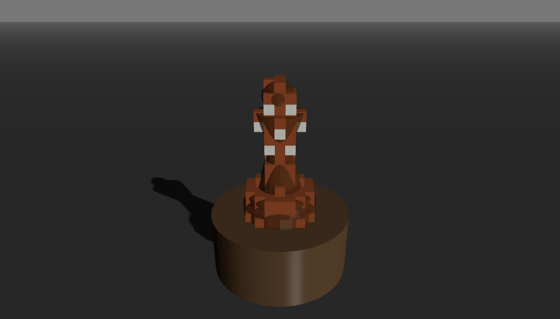

In [6]:
GIF_MODEL = RECORDINGS / "07_replay_model.gif"
# Close to the table and a bit above the block, as in notebook 02
CAMERA = ([0.75, -1.05, 0.85], [0.75, 0.0, 0.34])

if RECORD or not GIF_MODEL.exists():
    cell = Cell()
    env = swift.Swift()
    env.launch(realtime=True, browser=None, axes=False)
    add_table(env, cell)
    # Only what is left of the block
    rest = Voxels(voxels.centers[left], voxels.is_statue[left], voxels.size)
    cubes, _ = add_block(env, rest, cell)
    model, offset = add_model(env, MODELS / "Chess_Pawn.stl", STATUE_HEIGHT, cell, rgba=MODEL_RGBA)
    env.step(0.05)

    with recording(env, GIF_MODEL, camera=CAMERA):
        for phi in np.linspace(0.0, 2 * np.pi, 80):
            place_block(cubes, rest, cell, phi)
            model.T = cell.block_pose(phi) * offset
            env.step(0.05)
    env.close()

show_gif(GIF_MODEL)

## Summary

The next steps reuse `replay` and `add_model` (in `src/sculptor/scene.py`) to play any saved log back in Swift with the model on top, and the GIFs of section 3 for the slides.

The log of notebook 05 gives back its counts: 1596 of the 1607 marble cubes removed and none of the 208 statue cubes (section 1). What is left is the statue, 5.616 L against the 5.665 L of the model, and the 11 blocked marble cubes, 0.297 L (section 2). Section 3 plays the whole carving back and puts the model on top of the carved statue.